In [31]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, fetch_california_housing
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.svm import SVC, LinearSVR, SVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split

# Part I – SVMs: Load and Explore the Iris Dataset

In [32]:
iris = load_iris()
X = iris["data"]
y = iris["target"]
print(X.shape)
print(y.shape)
print(iris["target_names"])

(150, 4)
(150,)
['setosa' 'versicolor' 'virginica']


In [33]:
print(iris["feature_names"])

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [34]:
iris = load_iris(as_frame=True)          # as a pandas table, so we can pick columns by name
X = iris.data[["petal length (cm)", "petal width (cm)"]].values   # .values -> numpy array
y = (iris.target == 2).values            # True = Virginica, False = anything else

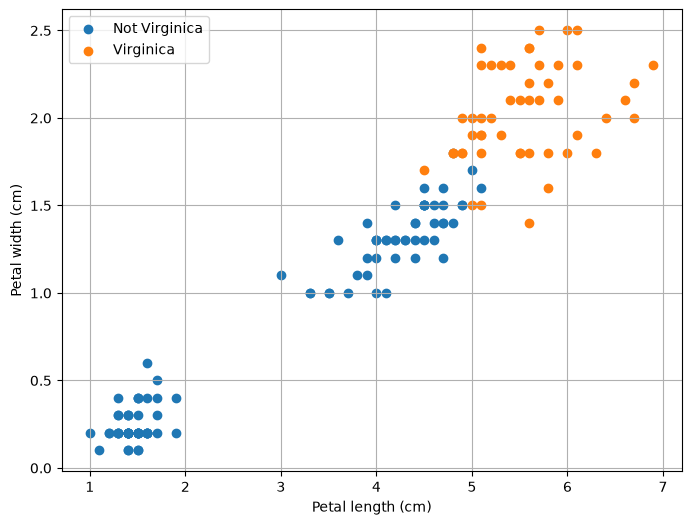

In [35]:
plt.figure(figsize=(8, 6))
plt.scatter(X[y == False, 0], X[y == False, 1], label="Not Virginica")
plt.scatter(X[y == True, 0],  X[y == True, 1],  label="Virginica")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend()
plt.grid()
plt.show()

# Task 1.1 – Explore the Classification Problem

**1. What is a decision boundary?**
**Answer:** The line (or surface) the model draws to split the classes. Points on one side are predicted as one class, and points on the other side as the other class.

**2. What is a margin?**
**Answer:** The empty “street” on both sides of the decision boundary, out to the closest points of each class. An SVM tries to make this street as wide as possible.

**3. What is a support vector?**
**Answer:** A training point that sits on the edge of the margin or inside it. These are the closest points to the boundary, and they alone decide where the boundary goes.

**4. How many observations are available in the iris dataset?**
**Answer:** 150 (50 of each species).

**5. What are the two classes in this experiment?**
**Answer:** Virginica (True, 50 flowers) and Not Virginica (False, 100 flowers: setosa + versicolor).

**6. Which two features are being used?**
**Answer:** Petal length (cm) and petal width (cm).

**7. Does the scatter plot suggest that the classes can be separated using a linear decision boundary?**
**Answer:** Mostly yes. A straight diagonal line separates almost all of them. A few points overlap near petal length ≈ 5 cm and width ≈ 1.5–1.8 cm, where large versicolor and small virginica flowers look alike. So it’s nearly linearly separable, but not perfectly.

# Part II – Feature Scaling

In [36]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [37]:
print("Before - min:", X.min(axis=0), "max:", X.max(axis=0), "mean:", X.mean(axis=0).round(2), "std:", X.std(axis=0).round(2))
print("After  - min:", X_scaled.min(axis=0).round(2), "max:", X_scaled.max(axis=0).round(2), "mean:", X_scaled.mean(axis=0).round(2), "std:", X_scaled.std(axis=0).round(2))

Before - min: [1.  0.1] max: [6.9 2.5] mean: [3.76 1.2 ] std: [1.76 0.76]
After  - min: [-1.57 -1.45] max: [1.79 1.71] mean: [-0. -0.] std: [1. 1.]


# Task 2.1 – Investigate Feature Scaling

**1. Why can feature scaling be important for SVMs?**
**Answer:** SVMs find the boundary by measuring distances between points. A feature with bigger numbers (petal length, range ~6) pulls harder on those distances than a feature with smaller numbers (petal width, range ~2.4), even if it isn’t more important. Scaling gives each feature a fair, equal say.

**2. What happens to the mean and scale of the features after standardization?**
**Answer:** Each feature’s mean becomes 0 and its standard deviation becomes 1. The shape of the data stays the same. It is only shifted and squeezed.

# Part III – Linear SVM Classification

In [38]:
svm_clf = SVC(kernel="linear", C=1)
svm_clf.fit(X_scaled, y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [39]:
y_pred = svm_clf.predict(X_scaled)
print(y_pred[:10])

[False False False False False False False False False False]


In [40]:
accuracy = accuracy_score(y, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9533333333333334


# Task 3.1 – Evaluate the Linear SVM

**1. What accuracy did you obtain?**
**Answer:** 0.953 (95.3%). That’s 143 of 150 correct, with 7 wrong.

**2. What does the model predict?**
**Answer:** For each flower, True (Virginica) or False (Not Virginica), based on its scaled petal length and width.

**3. Is evaluating only the training data sufficient?**
**Answer:** No. The model has already seen these exact flowers, so this is like marking a student with the same questions they practised on. It doesn’t tell us how well it does on new flowers.

**4. How could the model be evaluated more reliably?**
**Answer:** Use cross-validation, as in Lab II. Split the data into k folds (e.g. 5), train on 4 folds and test on the 1 left out, rotate 5 times, and average the scores. Every flower gets tested once by a model that never saw it. A separate test set also works.

# Part IV – Visualize the Decision Boundary

In [41]:
x0 = np.linspace(X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1, 200)
x1 = np.linspace(X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1, 200)
x0, x1 = np.meshgrid(x0, x1)

X_new = np.c_[x0.ravel(), x1.ravel()]
y_pred_grid = svm_clf.predict(X_new)
y_pred_grid = y_pred_grid.reshape(x0.shape)

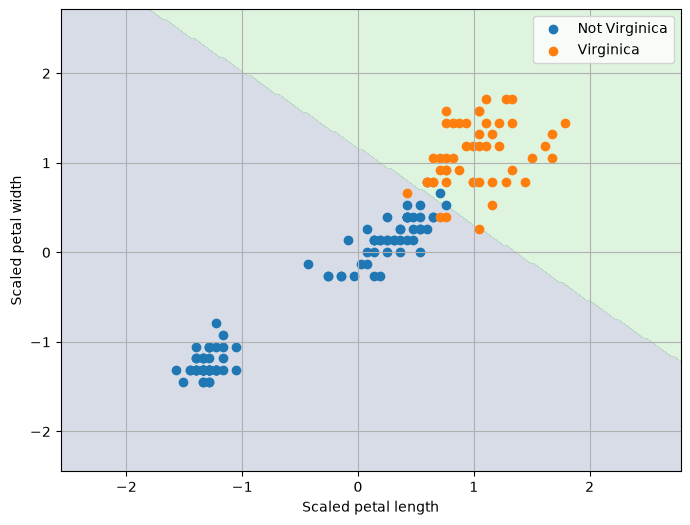

In [42]:
plt.figure(figsize=(8, 6))
plt.contourf(x0, x1, y_pred_grid, alpha=0.2)
plt.scatter(X_scaled[y == False, 0], X_scaled[y == False, 1], label="Not Virginica")
plt.scatter(X_scaled[y == True, 0],  X_scaled[y == True, 1],  label="Virginica")
plt.xlabel("Scaled petal length")
plt.ylabel("Scaled petal width")
plt.legend()
plt.grid()
plt.show()

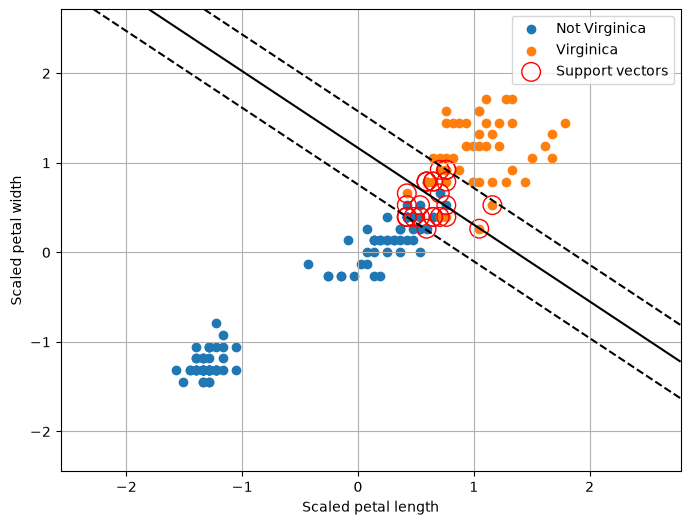

In [43]:
scores = svm_clf.decision_function(X_new).reshape(x0.shape)

plt.figure(figsize=(8, 6))
plt.contour(x0, x1, scores, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
plt.scatter(X_scaled[y == False, 0], X_scaled[y == False, 1], label="Not Virginica")
plt.scatter(X_scaled[y == True, 0],  X_scaled[y == True, 1],  label="Virginica")
sv = X_scaled[svm_clf.support_]
plt.scatter(sv[:, 0], sv[:, 1], s=180, facecolors="none", edgecolors="red", label="Support vectors")
plt.xlabel("Scaled petal length")
plt.ylabel("Scaled petal width")
plt.legend()
plt.grid()
plt.show()

# Task 4.1 – Interpret the Decision Boundary

**1. Where is the decision boundary?**
**Answer:** It’s a straight diagonal line from upper-left to lower-right, between the versicolor cluster and the virginica cluster. Flowers above/right of it (long, wide petals) are predicted Virginica. Flowers below/left are predicted Not Virginica.

**2. Which observations are closest to the boundary?**
**Answer:** The large versicolor and small virginica flowers where the two clouds touch, around 4.5–5.6 cm petal length and 1.4–1.8 cm width. The setosa cluster (bottom-left) is far away.

**3. What happens to the classification of observations near the boundary?**
**Answer:** It is uncertain, and that’s where the errors happen. All 7 misclassified flowers sit in this overlap zone. A tiny change in petal size could flip the prediction.

# Part V – Support Vectors and the Margin

In [44]:
print(svm_clf.support_)

[ 52  54  56  68  70  72  76  77  78  83  84  85  86 101 106 119 123 126
 127 129 133 134 138 142 146 149]


In [45]:
print(X_scaled[svm_clf.support_])

[[0.64908342 0.3957741 ]
 [0.47857113 0.3957741 ]
 [0.53540856 0.52740629]
 [0.42173371 0.3957741 ]
 [0.59224599 0.79067065]
 [0.64908342 0.3957741 ]
 [0.59224599 0.26414192]
 [0.70592084 0.65903847]
 [0.42173371 0.3957741 ]
 [0.76275827 0.52740629]
 [0.42173371 0.3957741 ]
 [0.42173371 0.52740629]
 [0.53540856 0.3957741 ]
 [0.76275827 0.92230284]
 [0.42173371 0.65903847]
 [0.70592084 0.3957741 ]
 [0.64908342 0.79067065]
 [0.59224599 0.79067065]
 [0.64908342 0.79067065]
 [1.16062026 0.52740629]
 [0.76275827 0.3957741 ]
 [1.0469454  0.26414192]
 [0.59224599 0.79067065]
 [0.76275827 0.92230284]
 [0.70592084 0.92230284]
 [0.76275827 0.79067065]]


# Task 5.1 – Investigate Support Vectors

**1. How many support vectors are there?**
**Answer:** 26 (13 from each class). Check with len(svm_clf.support_) or svm_clf.n_support_.

**2. Where are they located relative to the decision boundary?**
**Answer:** On the edges of the margin or inside it, all close to the boundary in the overlap zone. Some are even on the wrong side (the misclassified ones).

**3. Why are these observations important to the trained SVM?**
**Answer:** They are the only points that decide where the boundary goes. The other 124 points could be deleted and the boundary would stay exactly the same. It’s like the security fence: only the fans at the edge of the strip matter.

**4. What might happen if observations close to the decision boundary were removed from the training set?**
**Answer:** The boundary would move and the margin would probably get wider, because the “fence” would now be set by different points further out. The model could then make different (maybe worse) predictions on new flowers in the overlap zone. Removing far-away points would change nothing.

# Part VI – The C Hyperparameter

In [46]:
C_values = [0.01, 0.1, 1, 10, 100]

for C_value in C_values:
    svm_clf = SVC(kernel="linear", C=C_value)
    svm_clf.fit(X_scaled, y)
    predictions = svm_clf.predict(X_scaled)
    accuracy = accuracy_score(y, predictions)
    print("C =", C_value, "Accuracy =", accuracy)

C = 0.01 Accuracy = 0.96
C = 0.1 Accuracy = 0.96
C = 1 Accuracy = 0.9533333333333334
C = 10 Accuracy = 0.9666666666666667
C = 100 Accuracy = 0.96


In [47]:
for C_value in C_values:
    m = SVC(kernel="linear", C=C_value).fit(X_scaled, y)
    width = 2 / np.linalg.norm(m.coef_)
    cv = cross_val_score(Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear", C=C_value))]), X, y, cv=5).mean()
    print(f"C={C_value:<6} train={accuracy_score(y, m.predict(X_scaled)):.3f}  SVs={len(m.support_):<4} margin={width:.2f}  CV={cv:.3f}")

C=0.01   train=0.960  SVs=100  margin=3.39  CV=0.720
C=0.1    train=0.960  SVs=54   margin=1.26  CV=0.953
C=1      train=0.953  SVs=26   margin=0.62  CV=0.960
C=10     train=0.967  SVs=16   margin=0.34  CV=0.953
C=100    train=0.960  SVs=12   margin=0.22  CV=0.953


# Task 6.1 – Investigate C

**1. What happens when C is very small?**
**Answer:** The margin becomes very wide (3.39) and lots of points fall inside it (100 support vectors). The model accepts many margin violations. At C=0.01 the CV accuracy dropped to 0.72, so it was too relaxed and underfit on some folds.

**2. What happens when C becomes large?**
**Answer:** The margin gets very narrow (0.22) and only a few points touch it (12 support vectors). The model tries hard to classify every training point correctly.

**3. How does C affect the margin?**
**Answer:** Bigger C means a narrower margin. Smaller C means a wider margin. C sets the trade-off between “wide street” and “few training mistakes”.

**4. Does a higher training accuracy necessarily indicate better generalization?**
**Answer:** No. C=10 had the highest training accuracy (0.967), but C=1 had the best CV accuracy (0.960). Training accuracy only shows how well the model fits flowers it has already seen.

# Part VII – Nonlinear Classification with Polynomial Features

In [48]:
poly_svm_clf = Pipeline([
    ("poly_features", PolynomialFeatures(degree=3)),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=10))
])
poly_svm_clf.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly_features', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",3
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [49]:
print("Poly-feature SVM train accuracy:", accuracy_score(y, poly_svm_clf.predict(X)))
print("Number of features created:", poly_svm_clf.named_steps["poly_features"].n_output_features_)

Poly-feature SVM train accuracy: 0.96
Number of features created: 10


# Task 7.1 – Investigate Nonlinear Features

**1. What happens when the polynomial degree becomes larger?**
**Answer:** The number of features grows very fast (2 → 10 → 21 → 66). The boundary can bend more and more, so it can fit more complex shapes. Training also gets slower.

**2. What are the possible disadvantages of using very high-degree polynomial features?**
**Answer:**

Overfitting. The boundary wiggles to fit noise in the training data.
Feature explosion. With many original features, the count grows enormous. This makes training slow and uses lots of memory.
Huge numbers. Values like length¹⁰ get extremely big, so scaling becomes essential.

# Part VIII – Polynomial Kernel

In [50]:
poly_kernel_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="poly", degree=3, coef0=1, C=5))
])
poly_kernel_svm.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [51]:
predictions = poly_kernel_svm.predict(X)
accuracy_score(y, predictions)

0.96

# Task 8.1 – Understand the Polynomial Kernel

**1. What is the purpose of the polynomial kernel?**
**Answer:** It lets an SVM draw curved (nonlinear) boundaries. It acts as if polynomial features had been added, without actually computing them.

**2. What does the degree parameter control?**
**Answer:** How complex or bendy the boundary can be. A higher degree allows more curves.

**3. What could happen if the degree is too high?**
**Answer:** The model overfits. It bends around individual training points and noise. At degree 10 I got 0.98 training accuracy, but CV stayed around 0.96, so the extra training accuracy didn’t carry over to new data.

**4. Why can the kernel approach be more convenient than explicitly creating many polynomial features?**
**Answer:** It gets the same effect without creating and storing thousands of extra columns. That makes it faster and lighter on memory, especially with many original features or high degrees.

In [52]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1, gamma=1))
])
rbf_svm.fit(X, y)

predictions = rbf_svm.predict(X)
print(accuracy_score(y, predictions))

0.96


In [53]:
gamma_values = [0.01, 0.1, 1, 10, 100]

for gamma_value in gamma_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1, gamma=gamma_value))
    ])
    model.fit(X, y)
    predictions = model.predict(X)
    print("gamma =", gamma_value, "accuracy =", accuracy_score(y, predictions))

gamma = 0.01 accuracy = 0.9533333333333334
gamma = 0.1 accuracy = 0.9533333333333334
gamma = 1 accuracy = 0.96
gamma = 10 accuracy = 0.9666666666666667
gamma = 100 accuracy = 0.9933333333333333


# Task 8.2 – Investigate γ

**1. What happens when γ is very small?**
**Answer:** The boundary is very smooth, almost a straight line, because every point influences a wide area. At γ=0.01 the model is too simple and underfits: CV is only 0.84.

**2. What happens when γ becomes very large?**
**Answer:** Training accuracy goes very high (0.993 at γ=100), but CV accuracy drops (0.92). The model is memorising the training flowers.

**3. How can a very large γ lead to a complex decision boundary?**
**Answer:** Each training point only influences a tiny area around itself. So the boundary has to bend around individual points, forming small “islands” instead of one smooth line.

**4. How might an inappropriate value of γ lead to overfitting?**
**Answer:** If γ is too large, the model fits the exact positions of the training points, including noise and odd cases. It scores very well on data it has seen but worse on new data (0.993 train vs 0.92 CV). If γ is too small, the opposite happens: it underfits.

# Part IX – Comparing SVM Classification Models

In [54]:
linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1))
])

models = {
    "Linear SVM": linear_svm,
    "Polynomial Kernel": poly_kernel_svm,
    "RBF Kernel": rbf_svm
}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
    print(name, "Mean accuracy:", scores.mean(), "Std:", scores.std())

Linear SVM Mean accuracy: 0.9600000000000002 Std: 0.04898979485566355
Polynomial Kernel Mean accuracy: 0.9533333333333334 Std: 0.04521553322083511
RBF Kernel Mean accuracy: 0.9533333333333334 Std: 0.04521553322083511


# Task 9.1 – Compare the Models

**1. How do the models compare?**
**Answer: They’re practically the same, all about 95–96%. The difference (0.007) is much smaller than the standard deviation (~0.045), so it’s not a real difference. The data is almost linearly separable, so the curvy kernels have nothing extra to gain. The simplest model (linear) is as good as the others, so it’s the sensible choice.

**2. Which hyperparameters have the largest effect?**
**Answer: γ and C. γ moved CV accuracy from 0.84 (γ=0.01) up to 0.967 (γ=0.1) and back down to 0.92 (γ=100). C moved it from 0.72 (C=0.01) to 0.96 (C=1). The kernel choice itself mattered very little here.

**3. Why should cross-validation be used rather than comparing only training accuracy?**
**Answer: Training accuracy rewards memorising. γ=100 had the best training accuracy (0.993) but one of the worst CV scores (0.92). Cross-validation tests each model on flowers it didn’t train on, so it shows which model will actually work on new data. The standard deviation also shows how stable the result is. Here, one fold scored only 0.87, which tells us the score depends partly on which flowers end up in the test fold.

# Part X – SVM for Regression

In [55]:
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [57]:
linear_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", LinearSVR(epsilon=0.5, random_state=42, max_iter=10000))
])
linear_svr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [58]:
y_pred = linear_svr.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("RMSE:", rmse)

RMSE: 0.7504432215921479


# Task 10.1 – Interpret SVM Regression

**1. How is SVM regression different from SVM classification?**
**Answer:** Classification tries to keep points out of the margin, so the classes are separated by the widest street. Regression tries to fit as many points as possible inside a margin (tube) around the prediction line, and only points outside the tube count as errors. Classification outputs a class label. Regression outputs a number (house value).

**2. What does the ε parameter represent?**
**Answer:** The half-width of the tube. Prediction errors smaller than ε are ignored, and only errors bigger than ε are penalised. Here ε=0.5 means errors under $50,000 count as “close enough” during training. A bigger ε gives a more tolerant, simpler model. A smaller ε makes the model care about smaller errors.

# Part XI – Nonlinear SVM Regression

In [59]:
rbf_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf", C=100, gamma="scale", epsilon=0.1))
])
rbf_svr.fit(X_train, y_train)

y_pred = rbf_svr.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("RBF SVR RMSE:", rmse)

RBF SVR RMSE: 0.5657769203689085


# Task 11.1 – Experiment with SVR Hyperparameters

Use the first 5,000 training rows so each run takes seconds, not minutes:

In [60]:
X_small, y_small = X_train[:5000], y_train[:5000]

settings = [
    (100, "scale", 0.1),   # baseline
    (1,   "scale", 0.1),
    (10,  "scale", 0.1),
    (1000,"scale", 0.1),   # this one is slow (~1 min)
    (100, 0.01,   0.1),
    (100, 0.1,    0.1),
    (100, 1,      0.1),
    (100, 10,     0.1),
    (100, "scale", 0.01),
    (100, "scale", 0.5),
    (100, "scale", 1.0),
]

for C, gamma, eps in settings:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(kernel="rbf", C=C, gamma=gamma, epsilon=eps))
    ])
    model.fit(X_small, y_small)
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    train_rmse = np.sqrt(mean_squared_error(y_small, model.predict(X_small)))
    print(f"C={C:<5} gamma={str(gamma):<6} eps={eps:<5} test RMSE={test_rmse:.3f}  train RMSE={train_rmse:.3f}")

C=100   gamma=scale  eps=0.1   test RMSE=0.567  train RMSE=0.480
C=1     gamma=scale  eps=0.1   test RMSE=0.592  train RMSE=0.567
C=10    gamma=scale  eps=0.1   test RMSE=0.566  train RMSE=0.521
C=1000  gamma=scale  eps=0.1   test RMSE=0.643  train RMSE=0.442
C=100   gamma=0.01   eps=0.1   test RMSE=0.620  train RMSE=0.597
C=100   gamma=0.1    eps=0.1   test RMSE=0.566  train RMSE=0.495
C=100   gamma=1      eps=0.1   test RMSE=0.729  train RMSE=0.207
C=100   gamma=10     eps=0.1   test RMSE=0.929  train RMSE=0.097
C=100   gamma=scale  eps=0.01  test RMSE=0.575  train RMSE=0.483
C=100   gamma=scale  eps=0.5   test RMSE=0.574  train RMSE=0.493
C=100   gamma=scale  eps=1.0   test RMSE=0.654  train RMSE=0.587


**1. Which parameters had the greatest effect?**
**Answer:** γ, by far. Test RMSE went from 0.659 (γ=0.01) down to 0.603 (γ=0.1) and up to 0.917 (γ=10). C had a medium effect (0.601–0.688). ε had the smallest effect until it got large (1.0 → 0.681).

**2. Did increasing C always improve the model?**
**Answer:** No. Going from C=1 to C=100 improved it (0.637 → 0.601), but C=1000 was worse (0.688) and took much longer to train (~60 s vs ~8 s). Its training error kept dropping (0.472), which means it started overfitting.

**3. What happened when γ was increased?**
**Answer:** At first it improved (0.01 → 0.1). After that, the training RMSE kept falling (down to 0.096, almost perfect) while the test RMSE rose sharply (0.917). This is classic overfitting: each house only influences a tiny area, so the model memorises the training houses and predicts new ones badly.

# Part XII – Classification or Regression?

SVM can be used for both classification and regression, but the objective is different.

# Part XII – Classification or Regression?

|         | Classification   | Regression       |
|---------|------------------|------------------|
| Goal    | Predict a class  | Predict a number |
| Example | Iris species     | House price      |
| Model   | SVC              | SVR              |
| Output  | Class label      | Numerical value  |